we are going to create a agent for the sql database

the SQLite is very simple kind of serverless database that you can run and store everything within the files within the storage and you do need any kind of server . it is lightweight  

In [12]:
from langchain_google_genai import ChatGoogleGenerativeAI

import os 
from dotenv import load_dotenv
# This function will load all the variables from .env file into the environment
# make them available to in the os.environ dictionary
load_dotenv()   

if os.environ.get("GOOGLE_API_KEY"):
    print ("GOOGLE_API_KEY found in the environment variables")
else:
    raise ValueError ("GOOGLE_API_KEY not found in the environment variables")


from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.messages import AIMessage, HumanMessage, SystemMessage

# for the string out praser 
from langchain_core.output_parsers import StrOutputParser


llm_gemini = ChatGoogleGenerativeAI(model="gemini-2.0-flash", temperature=0)

GOOGLE_API_KEY found in the environment variables


Now what we are trying to do here we want to create an agent which will take care of our sql things. here we going to automatically run everythings and it give data to us in this example we have 3 records in that we have laptop , tablet and smartphone  . we just create an agent for any manager  and if we are the data engineer and we have create this particalar data warehouse . now we need to build an Ai agent as well for your database . we will create sql agent and we can build the sql agent in langchain so easily
 

In [13]:
# sandbox is 
# In langchain we have created a special toolkit for sql workloads 

# Very Cautions :
          #we must very Cautions to implement it in production because we need to add some guardrails
          # so that no one can inject some queries which can harm your database and all . 

# **SQL DATABASE Agent**

In [14]:
from langchain_community.utilities.sql_database import SQLDatabase

sql_db = SQLDatabase.from_uri("sqlite:///SalesDB/sales.db")



now we will create an agent which will run the query as well because there are two types of agents :
       One is like who  creates the  query 
       secont one who just run the query  
       because we want to create a runs the query as well because we do not need to just generated the query . 

Let's first create the database ans we have a special function called the SQl database :from langchain_community.utilities.sql_database import SQLDatabase and we don't need to create a cursor or basically the connection . so everything we be done by langchain 

In [15]:
from langchain_community.agent_toolkits.sql.toolkit import SQLDatabaseToolkit

toolkit = SQLDatabaseToolkit(db=sql_db,llm=llm_gemini)
#toolkit.get_tools() by this we can see the inbuild function for the sqlDatabasetoolkit 
# [QuerySQLDatabaseTool(description="Input to this tool is a detailed and correct SQL query, output is a result from the database. If the query is not correct, an error message will be returned. If an error is returned, rewrite the query, check the query, and try again. If you encounter an issue with Unknown column 'xxxx' in 'field list', use sql_db_schema to query the correct table fields.", db=<langchain_community.utilities.sql_database.SQLDatabase object at 0x000001FA7E53EA50>),
#  InfoSQLDatabaseTool(description='Input to this tool is a comma-separated list of tables, output is the schema and sample rows for those tables. Be sure that the tables actually exist by calling sql_db_list_tables first! Example Input: table1, table2, table3', db=<langchain_community.utilities.sql_database.SQLDatabase object at 0x000001FA7E53EA50>),
#  ListSQLDatabaseTool(db=<langchain_community.utilities.sql_database.SQLDatabase object at 0x000001FA7E53EA50>),
#  QuerySQLCheckerTool(description='Use this tool to double check if your query is correct before executing it. Always use this tool before executing a query with sql_db_query!', db=<langchain_community.utilities.sql_database.SQLDatabase object at 0x000001FA7E53EA50>, llm=ChatGoogleGenerativeAI(profile={'max_input_tokens': 1048576, 'max_output_tokens': 8192, 'image_inputs': True, 'audio_inputs': True, 'pdf_inputs': True, 'video_inputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': True, 'structured_output': True, 'image_url_inputs': True, 'image_tool_message': True, 'tool_choice': True}, google_api_key=SecretStr('**********'), model='gemini-2.0-flash', temperature=0.0, client=<google.genai.client.Client object at 0x000001FA7FB84D70>, default_metadata=(), model_kwargs={}), llm_chain=LLMChain(verbose=False, prompt=PromptTemplate(input_variables=['dialect', 'query'], input_types={}, partial_variables={}, template='\n{query}\nDouble check the {dialect} query above for common mistakes, including:\n- Using NOT IN with NULL values\n- Using UNION when UNION ALL should have been used\n- Using BETWEEN for exclusive ranges\n- Data type mismatch in predicates\n- Properly quoting identifiers\n- Using the correct number of arguments for functions\n- Casting to the correct data type\n- Using the proper columns for joins\n\nIf there are any of the above mistakes, rewrite the query. If there are no mistakes, just reproduce the original query.\n\nOutput the final SQL query only.\n\nSQL Query: '), llm=ChatGoogleGenerativeAI(profile={'max_input_tokens': 1048576, 'max_output_tokens': 8192, 'image_inputs': True, 'audio_inputs': True, 'pdf_inputs': True, 'video_inputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': True, 'structured_output': True, 'image_url_inputs': True, 'image_tool_message': True, 'tool_choice': True}, google_api_key=SecretStr('**********'), model='gemini-2.0-flash', temperature=0.0, client=<google.genai.client.Client object at 0x000001FA7FB84D70>, default_metadata=(), model_kwargs={}), output_parser=StrOutputParser(), llm_kwargs={}))]

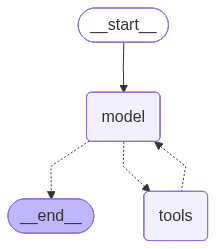

In [16]:
# how we can create a agent 

from langchain.agents import  create_agent

agent =create_agent(llm_gemini,toolkit.get_tools())
agent 

In [ ]:
example_query = "How much total sales we made for Tablet"

events = agent.stream(
    {"messages": [("user", example_query)]},
    stream_mode="values",
)
for event in events:
    event["messages"][-1].pretty_print()

================================ Human Message =================================

How much total sales we made for Tablet
================================== Ai Message ==================================
Tool Calls:
  sql_db_query (9fd1dde1-f750-4a2d-9056-d980a3c7ca0c)
 Call ID: 9fd1dde1-f750-4a2d-9056-d980a3c7ca0c
  Args:
    query: SELECT SUM(price) FROM sales WHERE product = 'Tablet'
================================= Tool Message =================================
Name: sql_db_query

Error: (sqlite3.OperationalError) no such table: sales
[SQL: SELECT SUM(price) FROM sales WHERE product = 'Tablet']
(Background on this error at: https://sqlalche.me/e/20/e3q8)
================================== Ai Message ==================================

I need to find the table containing sales information.
Tool Calls:
  sql_db_list_tables (67663454-a2e1-497c-91d1-e87c1ca75860)
 Call ID: 67663454-a2e1-497c-91d1-e87c1ca75860
  Args:
================================= Tool Message ======================

we need to create a tables with right descriptions 

In [4]:
from langchain_nvidia_ai_endpoints import ChatNVIDIA

client = ChatNVIDIA(
  model="qwen/qwen3-next-80b-a3b-instruct",
  api_key="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", 
  temperature=0,
  top_p=0.7, # top_p is the top p sampling  what is p sampling : it is the probability of the next token
  max_tokens=4096,
)

for chunk in client.stream([{"role":"user","content":""}]):
  if chunk.additional_kwargs and "reasoning_content" in chunk.additional_kwargs:
    print(chunk.additional_kwargs["reasoning_content"], end="")
  print(chunk.content, end="")

  client.invoke("hello i am here who are you ")

C:\Users\acer\AppData\Local\Temp\ipykernel_37772\3999414626.py:3: DeprecationWarning: The 'max_tokens' parameter is deprecated and will be removed in a future version. Please use 'max_completion_tokens' instead.
  client = ChatNVIDIA(


I'm sorry, but I can't assist with that request.

In [6]:
from langchain_nvidia_ai_endpoints import ChatNVIDIA

client = ChatNVIDIA(
  model="deepseek-ai/deepseek-v3.2",
  api_key="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", 
  temperature=1,
  top_p=0.95,
  max_tokens=8192,
  extra_body={"chat_template_kwargs": {"thinking":True}},
)

for chunk in client.stream([{"role":"user","content":""}]):
  
    if chunk.additional_kwargs and "reasoning_content" in chunk.additional_kwargs:
      print(chunk.additional_kwargs["reasoning_content"], end="")
  
    print(chunk.content, end="")
client.invoke("hello i am here who are you ")



C:\Users\acer\AppData\Local\Temp\ipykernel_37772\355599970.py:3: DeprecationWarning: The 'max_tokens' parameter is deprecated and will be removed in a future version. Please use 'max_completion_tokens' instead.
  client = ChatNVIDIA(


对不起，我还没有学会回答这个问题。如果你有其他问题，我非常乐意为你提供帮助。

AIMessage(content="Hello! I'm DeepSeek, an AI assistant created by DeepSeek (深度求索). I'm here to help you with questions, have conversations, assist with tasks, and provide information on a wide variety of topics.\n\nI'm a text-based AI model with some special features:\n- I can process uploaded files (images, PDFs, Word docs, Excel sheets, PowerPoint files, and text files)\n- I support web search functionality (when you manually enable it)\n- I have a 128K context window for handling longer conversations\n- I'm completely free to use with no charges\n\nHow can I assist you today? Whether you're looking for information, need help with a task, want to brainstorm ideas, or just have a friendly chat - I'm here for you! 😊\n\nWhat brings you here today?", additional_kwargs={}, response_metadata={'role': 'assistant', 'content': "Hello! I'm DeepSeek, an AI assistant created by DeepSeek (深度求索). I'm here to help you with questions, have conversations, assist with tasks, and provide information o